# 02. Features

This notebook adds the engineered features to the prepared table and saves what the modelling notebook reads.

| | File | Content |
|---|---|---|
| Input | `model_table.parquet` | From `01_prepare_data.ipynb`: target, 18 raw features, Elia benchmark, daylight and split flags, all areas |
| Input | `weather_belgium.parquet` | Read only for the exact coordinates of the weather point of the working area |
| Output | `features_table.parquet` | The working area only: keys, target, benchmark, flags, and every model input |
| Output | `features.json` | The list of model inputs, so `03_models.ipynb` uses exactly these columns |

**What is added**
1. **Sun geometry** (pvlib): solar elevation and azimuth, and **clear-sky irradiance**, the sunlight a cloudless sky would give at that place and time.
2. **Clear-sky index**: forecast irradiance divided by clear-sky irradiance. It separates the effect of cloud (index near 1 is clear, near 0 is overcast) from the effect of the sun's position.
3. **Diffuse fraction**: share of the forecast sunlight that is diffuse. High under cloud, low on clear days.
4. **Calendar**: hour of the day and day of the year, encoded as sine and cosine.
5. **Wind direction** as sine and cosine, since 359° and 1° are neighbours.

**Rules followed here**
- Every feature is known before the 11:00 day-ahead decision: it comes from the weather forecast, the sun's position or the calendar. **Nothing is derived from `measured`, `lf` or Elia's forecasts.**
- Nothing is learned from the data except the fill values for missing inputs, and those come from the training rows only.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib

TABLE_FILE = Path("model_table.parquet")
WEATHER_FILE = Path("weather_belgium.parquet")
OUT_FILE = Path("features_table.parquet")
FEATURES_FILE = Path("features.json")
PROVINCE = "Antwerp"            # the area the team is working on

# chart style (same as the other notebooks)
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
BLUE_LIGHT = "#b7d3f6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Load the working area

In [2]:
table = pd.read_parquet(TABLE_FILE)
df = table[table["region"] == PROVINCE].sort_values("datetime").reset_index(drop=True)
del table

WEATHER_RAW = ["shortwave_radiation", "direct_radiation", "diffuse_radiation", "direct_normal_irradiance",
               "cloud_cover", "cloud_cover_low", "cloud_cover_mid", "cloud_cover_high",
               "temperature_2m", "dew_point_2m", "relative_humidity_2m", "surface_pressure",
               "precipitation", "wind_speed_10m", "wind_gusts_10m", "wind_direction_10m"]

# Exact grid point Open-Meteo returned for this area (the weather file records it)
pt = pd.read_parquet(WEATHER_FILE, columns=["region", "latitude", "longitude"])
pt = pt[pt["region"] == PROVINCE].iloc[0]
LAT, LON = float(pt["latitude"]), float(pt["longitude"])

print(f"{PROVINCE}: {len(df):,} hourly rows, {df['is_daylight'].sum():,} in daylight")
print(f"Period: {df['datetime'].min()}  to  {df['datetime'].max()}")
print(f"Weather point: {LAT:.3f} N, {LON:.3f} E")

Antwerp: 22,919 hourly rows, 12,671 in daylight
Period: 2024-03-15 01:00:00+00:00  to  2026-10-25 23:00:00+00:00
Weather point: 51.213 N, 4.694 E


## 2. Sun geometry and clear-sky irradiance

Each row is labelled with the **end** of its hour, and the weather radiation is the average over that hour (see `01_prepare_data`). To match, the sun's position and the clear-sky irradiance are computed at the four quarter-hour midpoints inside the hour (for the hour ending 12:00: 11:07:30, 11:22:30, 11:37:30, 11:52:30) and averaged. Taking a single instant would be wrong near sunrise and sunset, when the sun moves quickly relative to the horizon.

Clear-sky irradiance uses the Ineichen model with pvlib's monthly climatological turbidity for this location. It needs nothing but the place and the time, so it is known any time in advance.

In [3]:
site = pvlib.location.Location(LAT, LON, tz="UTC", altitude=10)

offsets = pd.to_timedelta([-52.5, -37.5, -22.5, -7.5], unit="min")     # quarter-hour midpoints
end = pd.DatetimeIndex(df["datetime"])
parts = []
for off in offsets:
    t = end + off
    sp = site.get_solarposition(t)
    cs = site.get_clearsky(t, model="ineichen", solar_position=sp)
    parts.append(pd.DataFrame({
        "solar_elevation": sp["apparent_elevation"].to_numpy(),
        "solar_azimuth": sp["azimuth"].to_numpy(),
        "clearsky_ghi": cs["ghi"].to_numpy(),
        "clearsky_dni": cs["dni"].to_numpy(),
        "clearsky_dhi": cs["dhi"].to_numpy(),
    }))
sun = sum(parts) / len(parts)

# Azimuth is an angle: average it as a direction, not as a number
az = np.deg2rad(np.column_stack([p["solar_azimuth"] for p in parts]))
sun["solar_azimuth"] = np.rad2deg(np.arctan2(np.sin(az).mean(axis=1), np.cos(az).mean(axis=1))) % 360

for c in sun.columns:
    df[c] = sun[c].to_numpy()

df[["solar_elevation", "solar_azimuth", "clearsky_ghi", "clearsky_dni", "clearsky_dhi"]].describe().T[["mean", "min", "max"]]

,mean,min,max
solar_elevation,2.628,-61.982,61.935
solar_azimuth,182.592,0.023,359.990
clearsky_ghi,190.688,0.000,845.836
clearsky_dni,272.708,0.000,797.888
clearsky_dhi,44.534,0.000,147.338


### 2.1 Checks

Three checks that the sun geometry lines up with the data:
- **Daylight agreement.** Rows flagged as daylight (forecast irradiance above zero) should be the rows where clear-sky irradiance is above zero.
- **Clock alignment.** Forecast irradiance should line up best with clear-sky irradiance when the two are not shifted. A peak at another shift would mean a labelling error.
- **Physical ceiling.** Forecast irradiance should rarely exceed clear-sky irradiance by much (brief cloud-edge effects aside).

Daylight flag agrees with clear-sky > 0 in 99.31% of rows
  daylight flag but no clear-sky sun: 0 rows
  clear-sky sun but no forecast sunlight: 158 rows (mean clear-sky GHI there: 0.1 W/m²)


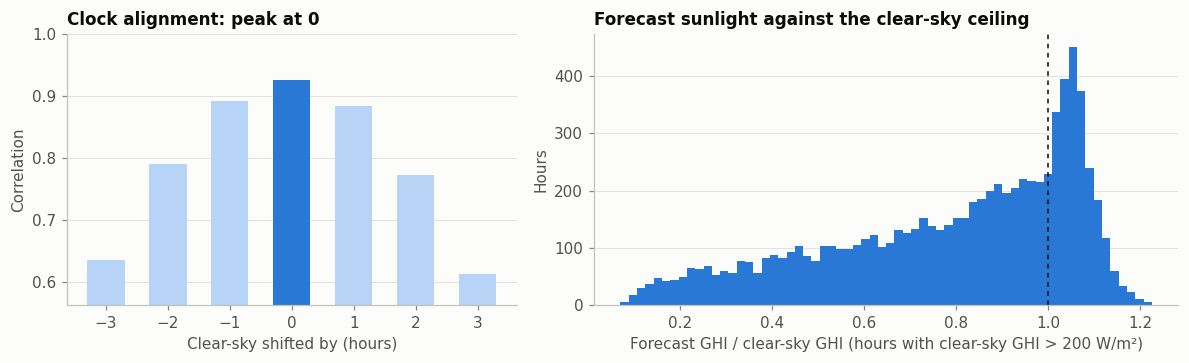

Correlation peaks at a shift of 0 h
Share of bright hours above 1.1 x clear-sky: 5.25%


In [4]:
cs_day = df["clearsky_ghi"] > 0
agree = (cs_day == df["is_daylight"]).mean()
print(f"Daylight flag agrees with clear-sky > 0 in {agree:.2%} of rows")
print(f"  daylight flag but no clear-sky sun: {(df['is_daylight'] & ~cs_day).sum():,} rows")
print(f"  clear-sky sun but no forecast sunlight: {(~df['is_daylight'] & cs_day).sum():,} rows "
      f"(mean clear-sky GHI there: {df.loc[~df['is_daylight'] & cs_day, 'clearsky_ghi'].mean():.1f} W/m²)")

shifts = range(-3, 4)
s = df.set_index("datetime")
corr = [s["shortwave_radiation"].corr(s["clearsky_ghi"].shift(k)) for k in shifts]

bright = df[df["clearsky_ghi"] > 200]
ratio = bright["shortwave_radiation"] / bright["clearsky_ghi"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.3]})
ax1.bar(list(shifts), corr, color=[BLUE if k == 0 else BLUE_LIGHT for k in shifts], width=0.6)
ax1.set_ylim(min(corr) - 0.05, 1)
ax1.set_xlabel("Clear-sky shifted by (hours)"); ax1.set_ylabel("Correlation")
ax1.set_title("Clock alignment: peak at 0", fontsize=11)
ax1.grid(axis="x", visible=False)
ax2.hist(ratio.clip(upper=1.6), bins=64, color=BLUE)
ax2.axvline(1, color=INK, linewidth=1, linestyle=(0, (3, 3)))
ax2.set_xlabel("Forecast GHI / clear-sky GHI (hours with clear-sky GHI > 200 W/m²)")
ax2.set_ylabel("Hours")
ax2.set_title("Forecast sunlight against the clear-sky ceiling", fontsize=11)
ax2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print(f"Correlation peaks at a shift of {list(shifts)[int(np.argmax(corr))]} h")
print(f"Share of bright hours above 1.1 x clear-sky: {(ratio > 1.1).mean():.2%}")

## 3. Clear-sky index and diffuse fraction

- **Clear-sky index** = forecast GHI / clear-sky GHI. It measures how much of the possible sunlight the forecast expects to get through the cloud.
- **Diffuse fraction** = forecast diffuse / forecast GHI. Under thick cloud almost all light is diffuse.

Both are ratios, and both explode when the denominator is close to zero (dawn, dusk, night). Two guards:
- the clear-sky denominator is floored at 100 W/m². Below that the sun is low (about 18% of daylight hours), output averages only about 1% of capacity, and the ratio becomes unstable: clear-sky models are least accurate near the horizon, so a small forecast divided by a tiny clear-sky value gives large, meaningless numbers. A first version with a 25 W/m² floor put many dawn and dusk hours at the cap. For these hours the index falls smoothly towards 0, and solar elevation carries the information instead;
- the diffuse fraction's denominator (forecast GHI) is floored at 10 W/m²;
- the clear-sky index is capped at 1.3 (forecasts above 1.3 times clear sky are rare, see 2.1).

At night both are set to 0. Night rows are not used in training or scoring, so this value never matters for the model.

In [5]:
night = ~df["is_daylight"]

df["clearsky_index"] = (df["shortwave_radiation"] / df["clearsky_ghi"].clip(lower=100)).clip(0, 1.3)
df["diffuse_fraction"] = (df["diffuse_radiation"] / df["shortwave_radiation"].clip(lower=10)).clip(0, 1)
df.loc[night, ["clearsky_index", "diffuse_fraction"]] = 0.0

day = df[df["is_daylight"]]
day[["clearsky_index", "diffuse_fraction"]].describe().T[["mean", "25%", "50%", "75%", "max"]]

,mean,25%,50%,75%,max
clearsky_index,0.679,0.380,0.747,1.001,1.300
diffuse_fraction,0.524,0.277,0.478,0.771,1.000


## 4. Calendar and wind direction

Hour and day of the year are cycles: 23:00 is next to 00:00, and 31 December is next to 1 January. Encoding each as a sine and a cosine puts neighbours close together, which a plain number 0 to 23 does not. Wind direction gets the same treatment.

The hour is the UTC hour ending, as in the rest of the project. Day of the year uses a 365.25-day cycle so leap years do not shift it.

In [6]:
hour = df["datetime"].dt.hour
doy = df["datetime"].dt.dayofyear
df["hour_sin"], df["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
df["doy_sin"], df["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)

wd = np.deg2rad(df["wind_direction_10m"])
df["wind_dir_sin"], df["wind_dir_cos"] = np.sin(wd), np.cos(wd)
df[["hour_sin", "hour_cos", "doy_sin", "doy_cos", "wind_dir_sin", "wind_dir_cos"]].describe().T[["min", "max"]]

,min,max
hour_sin,-1.000,1.000
hour_cos,-1.000,1.000
doy_sin,-1.000,1.000
doy_cos,-1.000,1.000
wind_dir_sin,-1.000,1.000
wind_dir_cos,-1.000,1.000


## 5. The feature list

**Model inputs** are the raw weather forecast (except wind direction in degrees, replaced by its sine and cosine) and the engineered features above.

**Left out on purpose**

| Column | Why it is not a model input |
|---|---|
| `measured`, `lf` | The target |
| `dayahead11hforecast` and its two bands | Elia's forecast is the benchmark the product is compared with. Feeding it in would turn our model into a correction of Elia's, a different product |
| `monitoredcapacity` | The target is already divided by capacity. Capacity grows steadily, so it acts as a clock: the test years have capacities never seen in training, and trees cannot extrapolate beyond them |
| `region` | One area only, so it is constant |
| `wind_direction_10m` in degrees | Replaced by its sine and cosine |
| `datetime`, `split`, `is_daylight` | Keys and flags |

In [7]:
ENGINEERED = ["solar_elevation", "solar_azimuth", "clearsky_ghi", "clearsky_dni", "clearsky_dhi",
              "clearsky_index", "diffuse_fraction",
              "hour_sin", "hour_cos", "doy_sin", "doy_cos", "wind_dir_sin", "wind_dir_cos"]
RAW_USED = [c for c in WEATHER_RAW if c != "wind_direction_10m"]
FEATURES = RAW_USED + ENGINEERED

FORBIDDEN = {"measured", "lf", "monitoredcapacity", "dayahead11hforecast",
             "dayahead11hconfidence10", "dayahead11hconfidence90", "region", "split", "is_daylight"}
assert not FORBIDDEN & set(FEATURES), "a target, benchmark or flag is in the feature list"
assert len(FEATURES) == len(set(FEATURES))

print(f"{len(RAW_USED)} raw weather features + {len(ENGINEERED)} engineered = {len(FEATURES)} model inputs")

15 raw weather features + 13 engineered = 28 model inputs


### 5.1 Missing values

Missing inputs would be filled with the **median of the training rows only**, so no information from the test period enters. The cell reports what it finds. (With the ECMWF weather file, nothing is expected to be missing.)

In [8]:
miss = df[FEATURES].isna().sum()
print(f"Missing values in model inputs: {int(miss.sum())}")
if miss.any():
    fill = df.loc[df["split"] == "train", FEATURES].median()
    display(pd.DataFrame({"missing": miss[miss > 0], "filled with (train median)": fill[miss > 0]}))
    df[FEATURES] = df[FEATURES].fillna(fill)
assert df[FEATURES].notna().all().all()

Missing values in model inputs: 0


### 5.2 Which features carry information? (training rows only)

A first look at how each input relates to the load factor, on **daylight training rows only**: the test period is not looked at before the final evaluation in `03_models`.

Plain correlation only sees straight-line relations, so the chart also shows the **mutual information**, which picks up curved ones too (for example the clear-sky index, whose effect on output is strongly non-linear). Both are single-variable views: inputs overlap a lot, and the models decide how to combine them.

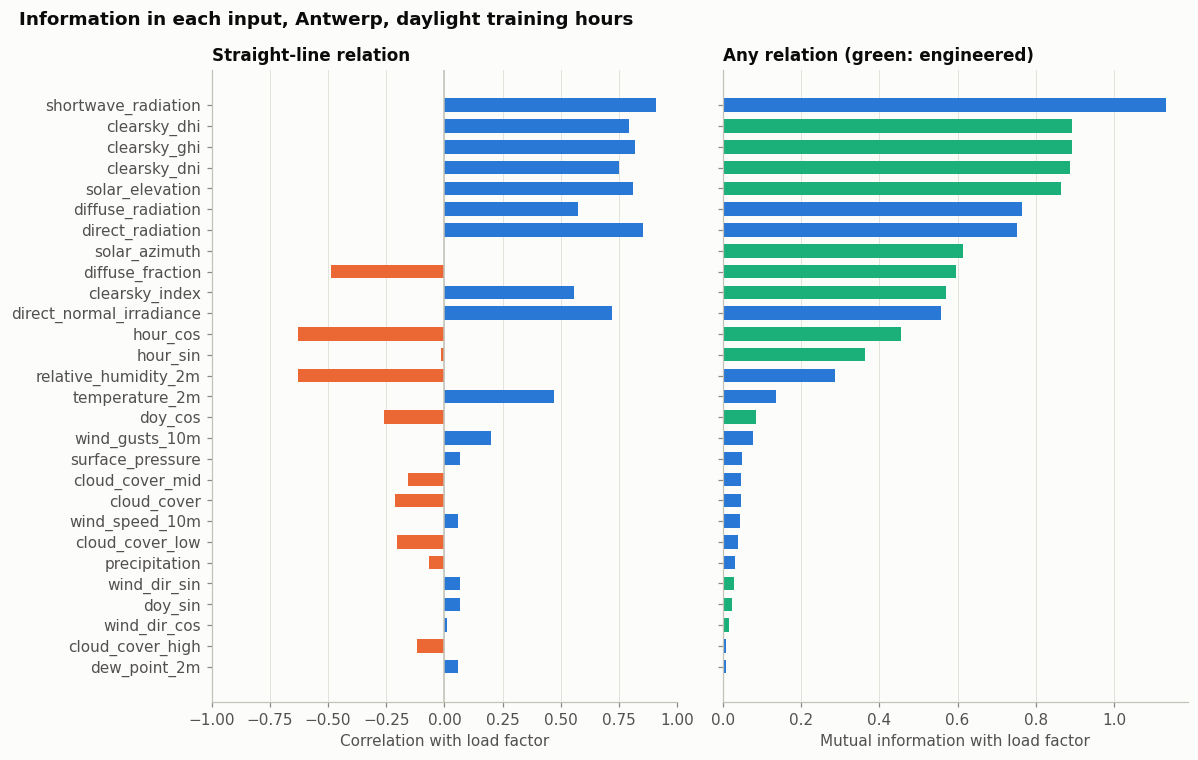

,correlation,mutual information
shortwave_radiation,0.908,1.132
clearsky_dhi,0.791,0.893
clearsky_ghi,0.817,0.892
clearsky_dni,0.750,0.887
solar_elevation,0.809,0.863
diffuse_radiation,0.575,0.764
direct_radiation,0.851,0.752
solar_azimuth,-0.003,0.613
diffuse_fraction,-0.486,0.597
clearsky_index,0.557,0.570


In [9]:
from sklearn.feature_selection import mutual_info_regression

tr = df[(df["split"] == "train") & df["is_daylight"]]
corr = tr[FEATURES].corrwith(tr["lf"])
sample = tr.sample(min(len(tr), 8000), random_state=0)
mi = pd.Series(mutual_info_regression(sample[FEATURES], sample["lf"], random_state=0), index=FEATURES)
info = pd.DataFrame({"correlation": corr, "mutual information": mi}).sort_values("mutual information")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 7), sharey=True)
ax1.barh(info.index, info["correlation"], color=[BLUE if v >= 0 else ORANGE for v in info["correlation"]], height=0.65)
ax1.axvline(0, color=AXIS, linewidth=1); ax1.set_xlim(-1, 1)
ax1.set_xlabel("Correlation with load factor"); ax1.set_title("Straight-line relation", fontsize=11)
ax2.barh(info.index, info["mutual information"], color=[AQUA if c in ENGINEERED else BLUE for c in info.index], height=0.65)
ax2.set_xlabel("Mutual information with load factor"); ax2.set_title("Any relation (green: engineered)", fontsize=11)
for ax in (ax1, ax2):
    ax.grid(axis="y", visible=False)
fig.suptitle(f"Information in each input, {PROVINCE}, daylight training hours", x=0.02, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.show()
info.sort_values("mutual information", ascending=False).head(10)

### 5.3 What the clear-sky index adds

Raw irradiance mixes two things: where the sun is, and how much cloud is in the way. The same irradiance can come from a high sun behind cloud or a low sun in a clear sky. The clear-sky index isolates the cloud part, and solar elevation (the colour) carries the sun part. Together they let a model treat the two effects separately, which raw irradiance alone does not allow.

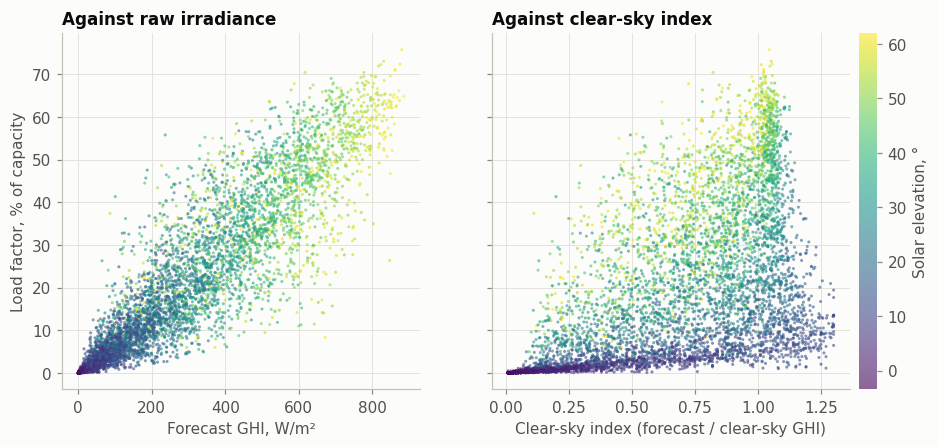

In [10]:
pl = tr.sample(min(len(tr), 6000), random_state=1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, x, label in [(ax1, "shortwave_radiation", "Forecast GHI, W/m²"),
                     (ax2, "clearsky_index", "Clear-sky index (forecast / clear-sky GHI)")]:
    sc = ax.scatter(pl[x], pl["lf"] * 100, c=pl["solar_elevation"], cmap="viridis", s=4, alpha=0.6, linewidths=0)
    ax.set_xlabel(label)
ax1.set_ylabel("Load factor, % of capacity")
ax1.set_title("Against raw irradiance", fontsize=11)
ax2.set_title("Against clear-sky index", fontsize=11)
cb = fig.colorbar(sc, ax=[ax1, ax2], pad=0.01); cb.set_label("Solar elevation, °"); cb.outline.set_visible(False)
plt.show()

## 6. Save

In [11]:
KEEP = ["datetime", "region", "split", "is_daylight", "lf", "measured", "monitoredcapacity",
        "dayahead11hforecast", "dayahead11hconfidence10", "dayahead11hconfidence90"]
out = df[KEEP + FEATURES].copy()

assert not out.duplicated("datetime").any()
assert out["lf"].between(0, 1).all()
assert out[FEATURES].notna().all().all()

out.to_parquet(OUT_FILE, index=False)
FEATURES_FILE.write_text(json.dumps({"province": PROVINCE, "features": FEATURES,
                                     "raw": RAW_USED, "engineered": ENGINEERED}, indent=2))
print(f"Saved {OUT_FILE}: {len(out):,} rows, {out.shape[1]} columns, {OUT_FILE.stat().st_size / 1e6:.1f} MB")
print(f"Saved {FEATURES_FILE}: {len(FEATURES)} model inputs")
out.groupby("split").agg(rows=("lf", "size"), daylight_rows=("is_daylight", "sum"),
                         first=("datetime", "min"), last=("datetime", "max")).loc[["train", "test"]]

Saved features_table.parquet: 22,919 rows, 38 columns, 2.2 MB
Saved features.json: 28 model inputs


,rows,daylight_rows,first,last
split,,,,
train,14159,7986,2024-03-15 01:00:00+00:00,2025-10-25 23:00:00+00:00
test,8760,4685,2025-10-26 00:00:00+00:00,2026-10-25 23:00:00+00:00


## What the next notebook receives

`features_table.parquet`, one row per hour for the working area, and `features.json`:

- **Model inputs:** the columns listed in `features.json` under `features`. Use exactly these, so every model sees the same information.
- **Target:** `lf`. Multiply by `monitoredcapacity` to get MW.
- **Benchmark:** `dayahead11hforecast` (MW). Divide by `monitoredcapacity` to compare with `lf`. Never a model input.
- **Rows to train and score on:** `is_daylight == True`. `split` says train (before 2025) or test (2025 on). Tune with time-ordered folds inside the training years; look at the test rows once, at the end.
- **Naive benchmark:** build it in `03_models` from `lf` 24 hours earlier, matched on the clock. It is a benchmark, not an input: at 11:00 on the day before, the afternoon of that same day has not happened yet, so it is not fully known at decision time.